# Ettin early-exit ablations: frozen backbone, elastic depth and dimensions

One self-contained notebook for Colab A100 / VS Code. Start from the successful Ettin pilot and compare
**raw pooling, pooled residual MLP, token-wise residual MLP, and a copied Transformer block** at every intermediate layer.
Train only side branches; the full-depth encoder stays unchanged. Evaluate **128 / 256 / 384D** at each exit, with both
same-exit retrieval and early-exit queries searching the original full-depth corpus at the matching dimension.

All code is inline. Drive stores resumable head checkpoints, benchmark tables, plots, exports and final sanity checks.
Requires the pilot's `config.json`, retained `checkpoints/student/`, and `pairs.json`. No GTE model/cache or other notebook execution is needed.
This compares frozen heads; joint backbone 2D Matryoshka training is a separate future experiment.

In [2]:
# Install into this notebook's kernel. Keep Colab's CUDA-enabled PyTorch.
# Restart the kernel after this cell if it already imported different versions.
%pip install -q transformers==5.1.0 datasets==4.5.0 accelerate==1.12.0 sentence-transformers==5.2.2 safetensors
%pip -q install matplotlib

In [3]:
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HOME'] = '/content/hf-cache' if os.path.isdir('/content') else '/tmp/encoder-hf-cache'
import copy, gc, hashlib, json, math, random, shutil, time, uuid
from pathlib import Path
from collections import defaultdict
from contextlib import nullcontext
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file, save_file
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')
DEVICE = 'cuda'
assert torch.cuda.is_available(), 'Select an A100 GPU runtime in Colab.'
assert torch.cuda.is_bf16_supported(), 'This notebook uses BF16 on a supported GPU.'
print(torch.cuda.get_device_name(), 'PyTorch:', torch.__version__)
torch.set_float32_matmul_precision('high')
import csv
import matplotlib.pyplot as plt
from transformers.models.modernbert.modeling_modernbert import create_bidirectional_mask, create_bidirectional_sliding_window_mask

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NVIDIA A100-SXM4-40GB PyTorch: 2.11.0+cu128


## Settings

Use a new destination for changed hyperparameters. `EXIT_DEPTHS=None` means every layer before the final layer.
Defaults train 3 head banks × 300 updates; each update trains every exit in that bank on the same batch.
Start with `STEPS=20` and `EXIT_DEPTHS=[2,5,8]` under a separate smoke-test run name if desired.
A single seed is a pilot comparison; set `SEEDS=[42,43,44]` for repeated runs. All variants within a seed see the same batch order.

In [4]:
SOURCE_RUN = Path('/content/drive/MyDrive/encoder_experiments/ettin-pilot-01')
SOURCE_STAGE = 'student'
SOURCE_CHOICE = 'best'  # or an integer retained step, e.g. 400
RUN_NAME = 'ettin-exit-ablation-01'
ROOT = Path('/content/drive/MyDrive/encoder_experiments') / RUN_NAME
LOCAL = Path('/content/encoder-work') / RUN_NAME
assert ROOT.resolve()!=SOURCE_RUN.resolve(), 'Keep a separate destination.'
ROOT.mkdir(parents=True,exist_ok=True);LOCAL.mkdir(parents=True,exist_ok=True)
EXIT_DEPTHS = None
DIMS = [128,256,384]
KINDS = ['pooled_mlp','token_mlp','transformer']  # raw pooling + full depth always included
SEEDS = [42]
STEPS = 300
BATCH_SIZE = 16
LEARNING_RATE = 1e-4
MLP_EXPANSION = 2
EVAL_EVERY = 50
CHECKPOINT_EVERY = 50
VALIDATION_ROWS = 256
RUN_LATENCY = True
LATENCY_BATCHES = [1,16]
LATENCY_LENGTHS = [32,128,256]
LATENCY_REPEATS = 10
def digest(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def text_id(s):
    return hashlib.sha256(' '.join(s.split()).casefold().encode()).hexdigest()
def write_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.tmp-'+uuid.uuid4().hex)
    temp.write_text(json.dumps(obj,indent=2,ensure_ascii=False));os.replace(temp,path)
def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024),b''):h.update(part)
    return h.hexdigest()


source_contract=json.loads((SOURCE_RUN/'config.json').read_text())
assert source_contract['config']['experiment']=='ettin'
CFG=copy.deepcopy(source_contract['config'])
CFG.update(experiment='ettin-frozen-exit-ablation',batch_size=BATCH_SIZE,accumulation=1,
           student_lr=LEARNING_RATE,weight_decay=.01,warmup_fraction=.1,
           eval_every=EVAL_EVERY,checkpoint_every=CHECKPOINT_EVERY,log_every=10)
GTE=source_contract['gte'];ETTIN=source_contract['ettin'];NANO=source_contract['nano']
assert STEPS>0 and BATCH_SIZE>1 and EVAL_EVERY>0 and CHECKPOINT_EVERY>0
assert KINDS and len(KINDS)==len(set(KINDS)) and set(KINDS)<={'pooled_mlp','token_mlp','transformer'}
assert SEEDS and len(SEEDS)==len(set(SEEDS))
seed_everything(SEEDS[0])

## Select the pilot checkpoint and lock experiment identity

In [5]:
# Only load your own training checkpoints. Verify the source manifest and bytes first.
def verified_source_generations():
    parent=SOURCE_RUN/'checkpoints'/SOURCE_STAGE
    candidates=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and
                       (p/'COMMITTED.json').exists()),reverse=True)
    expected=digest(source_contract)
    for path in candidates:
        meta=json.loads((path/'COMMITTED.json').read_text())
        if meta['contract']!=expected:
            raise RuntimeError(f'Source checkpoint belongs to another config: {path}')
        yield path,meta

def read_source(path,meta):
    local=LOCAL/'source-checkpoint.pt'
    shutil.copyfile(path/'state.pt',local)
    if file_sha(local)!=meta['sha256']:
        raise ValueError(f'Source checkpoint checksum mismatch: {path}')
    state=torch.load(local,map_location='cpu',weights_only=False)
    assert state['contract']==digest(source_contract) and state['family']=='ettin'
    assert state['step']==meta['step'] and state['stage']==SOURCE_STAGE
    return state

def select_source_checkpoint():
    lock=ROOT/'source.json'
    if lock.exists():
        selected=json.loads(lock.read_text())
        assert selected['run']==str(SOURCE_RUN) and selected['stage']==SOURCE_STAGE
        assert selected['choice']==SOURCE_CHOICE, 'Source selection changed: choose a new RUN_NAME.'
        path=Path(selected['checkpoint'])
        meta=json.loads((path/'COMMITTED.json').read_text())
        assert meta['sha256']==selected['sha256'] and meta['contract']==digest(source_contract)
        return selected,read_source(path,meta)
    generations=list(verified_source_generations())
    if not generations:raise FileNotFoundError('No completed source checkpoints. Finish notebook 02 first.')
    latest=None
    for path,meta in generations:
        try:
            latest=read_source(path,meta);break
        except (ValueError,OSError,EOFError) as error:
            print('Skipping unreadable generation:',path,error)
    if latest is None:raise RuntimeError('No readable source checkpoint remains.')
    step=latest['best_step'] if SOURCE_CHOICE=='best' else latest['step'] if SOURCE_CHOICE=='latest' else int(SOURCE_CHOICE)
    if latest['step']!=step:
        del latest
        choices=[(p,x) for p,x in generations if x['step']==step]
        if not choices:raise FileNotFoundError(f'Source step {step} was not retained.')
        path,meta=choices[0];latest=read_source(path,meta)
    selected=dict(run=str(SOURCE_RUN),stage=SOURCE_STAGE,choice=SOURCE_CHOICE,step=step,
                  checkpoint=str(path),sha256=meta['sha256'])
    write_json(lock,selected)
    return selected,latest

source_info,source_state=select_source_checkpoint()
DATA_ID=source_state['data_id']

NUM_LAYERS=source_state['spec']['num_hidden_layers']
WIDTH=source_state['spec']['hidden_size']
DEPTHS=list(range(1,NUM_LAYERS)) if EXIT_DEPTHS is None else list(EXIT_DEPTHS)
assert DEPTHS and DEPTHS==sorted(set(DEPTHS)) and all(1<=d<NUM_LAYERS for d in DEPTHS)
assert DIMS==sorted(set(DIMS)) and all(0<d<=WIDTH for d in DIMS) and WIDTH in DIMS
contract=dict(config=CFG,source=source_info,depths=DEPTHS,dimensions=DIMS,kinds=KINDS,seeds=SEEDS,
              steps=STEPS,mlp_expansion=MLP_EXPANSION,validation_rows=VALIDATION_ROWS,
              losses=dict(prefix_alignment=1.,prefix_ranking=1.,full_geometry=.2),
              selection='mean_validation_mrr_across_depth_dimension_and_same_or_cross_exit',
              initialization='zero_residual_mlps_or_copied_final_transformer',implementation=1)
CONTRACT_ID=digest(contract)
if (ROOT/'config.json').exists():
    assert json.loads((ROOT/'config.json').read_text())==contract, 'Settings changed: use a new RUN_NAME.'
else:write_json(ROOT/'config.json',contract)
print('Source step:',source_info['step'],'Depths:',DEPTHS,'Dimensions:',DIMS,'Width:',WIDTH)

Source step: 400 Depths: [1, 2, 3, 4, 5, 6, 7, 8, 9] Dimensions: [128, 256, 384] Width: 384


In [6]:
def mean_pool(hidden, mask):
    mask = mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden.float()*mask).sum(1) / mask.sum(1).clamp_min(1)

# Input adapters belong to the model, so evaluation, training and export use the same tokenizer/pooling.
class EmbeddingModel(nn.Module):
    def __init__(self, backbone, tokenizer, output_dim, family, spec):
        super().__init__()
        self.backbone, self.tokenizer = backbone, tokenizer
        self.output_dim, self.family, self.spec = output_dim, family, copy.deepcopy(spec)
        self.max_length = CFG['max_length']
        # Ettin's alignment head is training-only. Retrieval always uses its native 384/512 dimensions.
        self.align = nn.Identity() if output_dim == 768 else nn.Linear(output_dim,768,bias=False)
    def forward(self, texts):
        tokens = self.tokenizer(texts, padding=True, truncation=True, max_length=self.max_length,
                                return_tensors='pt').to(next(self.parameters()).device)
        if self.family == 'neobert':
            h = self.backbone(tokens['input_ids'], tokens['attention_mask'])
        else:
            h = self.backbone(**tokens).last_hidden_state
        return mean_pool(h, tokens['attention_mask'])

def count_parameters(model):
    return dict(total=sum(p.numel() for p in model.parameters()),
                backbone=sum(p.numel() for p in model.backbone.parameters()),
                training_only_alignment=sum(p.numel() for p in model.align.parameters()))

In [7]:
spec=copy.deepcopy(source_state['spec']);model_type=spec.pop('model_type')
assert model_type=='modernbert'
backbone=AutoModel.from_config(AutoConfig.for_model(model_type,**spec),attn_implementation='sdpa')
tokenizer=AutoTokenizer.from_pretrained(ETTIN['id'],revision=ETTIN['revision'])
student=EmbeddingModel(backbone,tokenizer,WIDTH,'ettin',source_state['spec'])
student.load_state_dict(source_state['model'],strict=True)
student.to(DEVICE).eval().requires_grad_(False)
backbone.gradient_checkpointing_disable()
del source_state
corpus=json.loads((SOURCE_RUN/'pairs.json').read_text())
assert digest(corpus)==DATA_ID, 'Training pairs do not match the source checkpoint.'
assert len(corpus['train'])>=BATCH_SIZE and len(corpus['validation'])>0
VALIDATION=corpus['validation'][:VALIDATION_ROWS]
assert VALIDATION

def backbone_digest():
    h=hashlib.sha256()
    for name,t in backbone.state_dict().items():
        h.update(name.encode());h.update(t.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
BACKBONE_SHA=backbone_digest()
print('Frozen backbone parameters:',sum(p.numel() for p in backbone.parameters()))
print('Training/validation/test rows:',*[len(corpus[x]) for x in ('train','validation','test')])
print('Transformer exit initialization: final block, attention type:',backbone.layers[-1].attention_type)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Frozen backbone parameters: 31883136
Training/validation/test rows: 19981 256 256
Transformer exit initialization: final block, attention type: full_attention


## Exact prefix execution and branch definitions

The loop below mirrors the pinned ModernBERT forward method, including padding masks, local/global attention and RoPE.
It executes only the requested prefix at inference. A training pass executes the frozen backbone once through all layers,
then trains branches on detached states. Full-depth targets come from the trained Ettin itself.

MLPs start as identity residuals; pooled and token-wise variants use identical shapes and initialization per seed.
The transformer branch copies the final trained block (including its attention type), then applies the original final normalization.
All branches preserve the original final normalization as frozen parameters. This is a practical architecture comparison,
not a parameter-matched or initialization-matched causal test of attention alone.

In [8]:
def tokenize(texts):
    return tokenizer(texts,padding=True,truncation=True,max_length=CFG['max_length'],return_tensors='pt').to(DEVICE)

@torch.no_grad()
def frozen_features(tokens,depths):
    backbone.eval()
    last=max(depths);assert 1<=last<=NUM_LAYERS
    h=backbone.embeddings(input_ids=tokens['input_ids'])
    positions=torch.arange(h.shape[1],device=h.device).unsqueeze(0)
    mask_args=dict(config=backbone.config,input_embeds=h,attention_mask=tokens['attention_mask'])
    masks={'full_attention':create_bidirectional_mask(**mask_args),
           'sliding_attention':create_bidirectional_sliding_window_mask(**mask_args)}
    rope={kind:backbone.rotary_emb(h,positions,kind) for kind in set(backbone.config.layer_types)}
    outputs={}
    for depth,layer in enumerate(backbone.layers[:last],1):
        h=layer(h,attention_mask=masks[layer.attention_type],position_embeddings=rope[layer.attention_type])
        if depth in depths:outputs[depth]=h.detach()
    return outputs,dict(masks=masks,rope=rope)

def native_pool(hidden,mask):
    return mean_pool(backbone.final_norm(hidden),mask)

class ResidualMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.up=nn.Linear(WIDTH,WIDTH*MLP_EXPANSION)
        self.down=nn.Linear(WIDTH*MLP_EXPANSION,WIDTH)
        nn.init.zeros_(self.down.weight);nn.init.zeros_(self.down.bias)
    def forward(self,x):return x+self.down(F.gelu(self.up(x)))

class ExitHead(nn.Module):
    def __init__(self,kind):
        super().__init__();self.kind=kind
        self.norm=copy.deepcopy(backbone.final_norm).requires_grad_(False)
        if kind=='transformer':
            self.block=copy.deepcopy(backbone.layers[-1]).requires_grad_(True)
            self.block.gradient_checkpointing=False
        else:self.mlp=ResidualMLP()
    def forward(self,h,mask,context):
        if self.kind=='transformer':
            typ=self.block.attention_type
            h=self.block(h,attention_mask=context['masks'][typ],position_embeddings=context['rope'][typ])
            return mean_pool(self.norm(h),mask)
        h=self.norm(h)
        if self.kind=='pooled_mlp':return self.mlp(mean_pool(h,mask))
        return mean_pool(self.mlp(h),mask)

class ExitBank(nn.Module):
    def __init__(self,kind,seed):
        super().__init__();seed_everything(seed)
        self.kind=kind;self.family='ettin-exits'
        self.spec=dict(kind=kind,seed=seed,depths=DEPTHS,width=WIDTH,expansion=MLP_EXPANSION,source=source_info['sha256'])
        self.heads=nn.ModuleDict({str(d):ExitHead(kind) for d in DEPTHS})
    def forward(self,depth,h,mask,context):return self.heads[str(depth)](h,mask,context)

def early_raw(tokens,depth,bank=None):
    features,context=frozen_features(tokens,[depth])
    if depth==NUM_LAYERS or bank is None:return native_pool(features[depth],tokens['attention_mask'])
    return bank(depth,features[depth],tokens['attention_mask'],context)

@torch.inference_mode()
def encode_profiles(texts,bank=None,batch_size=None):
    if bank is not None:bank.eval()
    result={d:[] for d in DEPTHS+[NUM_LAYERS]}
    for start in range(0,len(texts),batch_size or CFG['teacher_batch_size']):
        tokens=tokenize(texts[start:start+(batch_size or CFG['teacher_batch_size'])])
        with torch.autocast('cuda',dtype=torch.bfloat16):
            features,context=frozen_features(tokens,DEPTHS+[NUM_LAYERS])
            for depth in result:
                z=native_pool(features[depth],tokens['attention_mask']) if bank is None or depth==NUM_LAYERS else bank(depth,features[depth],tokens['attention_mask'],context)
                z=z.float().cpu()
                assert torch.isfinite(z).all() and (z.norm(dim=-1)>1e-8).all(), 'Invalid embeddings'
                result[depth].append(z)
    return {depth:torch.cat(parts) for depth,parts in result.items()}

In [9]:
# Confirm the custom full-depth path matches the unchanged pilot, and exits skip later layers.
probe=['Reset my password.','Visit a library to borrow a book.']
tokens=tokenize(probe)
with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
    expected=student(probe);actual=early_raw(tokens,NUM_LAYERS)
torch.testing.assert_close(expected,actual,atol=1e-5,rtol=1e-4)
counts=[0]*NUM_LAYERS
hooks=[layer.register_forward_hook(lambda module,args,output,i=i:counts.__setitem__(i,counts[i]+1)) for i,layer in enumerate(backbone.layers)]
try:
    with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):early_raw(tokens,min(DEPTHS))
finally:
    for hook in hooks:hook.remove()
assert counts==[int(i<min(DEPTHS)) for i in range(NUM_LAYERS)],counts
print('Full-path parity passed. Actual early-exit block calls:',counts)

Full-path parity passed. Actual early-exit block calls: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Objectives and held-out selection

Every head receives the same weighted objective, averaged over dimensions: (1) cosine alignment to the matching
prefix of the frozen final embedding, (2) labeled in-batch/explicit-negative ranking, (3) pairwise similarity matching
to the **full 384D teacher geometry**. The latter encourages small vectors to preserve full-vector relationships.
These objectives can compete; this is an experimental recipe inspired by FastBERT and Matryoshka-Adaptor.

Each bank is selected by mean validation MRR over depths, dimensions, and both retrieval modes. Validation retrieves
within the held-out positive-passage pool; duplicate positives count as relevant and irrelevant ties rank conservatively.
Step zero can win. NanoBEIR and test rows never select checkpoints. The raw baseline is never trained.

In [10]:
def flatten_pairs(rows):
    # This ordering is used for BOTH students and targets.
    return [r[k] for k in ('query','positive','negative') for r in rows]

def contrastive_loss(z, rows, dim):
    n=len(rows); z=F.normalize(z[:,:dim].float(),dim=-1)
    q,p,neg=z.split(n)
    docs=torch.cat((p,neg))
    logits=q@docs.T/CFG['temperature']
    doc_ids=[text_id(r[k]) for k in ('positive','negative') for r in rows]
    pos_ids=[text_id(r['positive']) for r in rows]
    query_ids=[text_id(r['query']) for r in rows]
    # Exclude duplicated positives and all alternative passages of duplicate queries from negatives.
    valid=torch.ones((n,2*n),device=z.device,dtype=torch.bool)
    for i in range(n):
        for j in range(2*n):
            if j!=i and (doc_ids[j]==pos_ids[i] or (j%n!=i and query_ids[j%n]==query_ids[i])):
                valid[i,j]=False
    logits=logits.masked_fill(~valid,torch.finfo(logits.dtype).min)
    return F.cross_entropy(logits,torch.arange(n,device=z.device))


def branch_loss(raw,target,rows):
    full_target=F.normalize(target.float(),dim=-1)
    pairmask=~torch.eye(len(raw),device=raw.device,dtype=torch.bool)
    terms=[]
    for dim in DIMS:
        z=F.normalize(raw[:,:dim].float(),dim=-1)
        t=F.normalize(target[:,:dim].float(),dim=-1)
        align=(1-(z*t).sum(-1)).mean()
        relation=F.mse_loss((z@z.T)[pairmask],(full_target@full_target.T)[pairmask])
        terms.append(align+contrastive_loss(raw,rows,dim)+.2*relation)
    return torch.stack(terms).mean()

@torch.inference_mode()
def validate_bank(bank,rows=None):
    rows=VALIDATION if rows is None else rows
    vectors=encode_profiles([r['query'] for r in rows]+[r['positive'] for r in rows],bank)
    ids=[text_id(r['positive']) for r in rows]
    relevant=torch.tensor([[a==b for b in ids] for a in ids])
    profiles=[];n=len(rows)
    for depth in DEPTHS:
        for dim in DIMS:
            q=F.normalize(vectors[depth][:n,:dim],dim=-1)
            for mode,pdepth in [('same_exit',depth),('full_corpus',NUM_LAYERS)]:
                p=F.normalize(vectors[pdepth][n:,:dim],dim=-1)
                scores=q@p.T;positive=scores.masked_fill(~relevant,-float('inf')).max(1).values
                ranks=1+((scores>=positive[:,None]-1e-6)&~relevant).sum(1)
                profiles.append(dict(depth=depth,dimension=dim,mode=mode,
                                     mrr=float((1/ranks.float()).mean()),hit1=float((ranks==1).float().mean())))
    return dict(selection_score=float(np.mean([r['mrr'] for r in profiles])),queries=n,profiles=profiles)

## Resumable head-only checkpoints

In [11]:
# Completed generations are immutable. Upload to a temporary directory; COMMITTED.json is written last.
# Resume discovers the newest verified generation, rather than trusting a possibly stale "latest" pointer.
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), cpu=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())
def restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['cpu'])
    if torch.cuda.is_available(): torch.cuda.set_rng_state_all(state['cuda'])

def save_checkpoint(stage, step, model, optimizer, scheduler, sampler, best_metric, best_step, total_steps):
    parent=ROOT/'checkpoints'/stage; parent.mkdir(parents=True,exist_ok=True)
    generation=f'{step:08d}-{uuid.uuid4().hex[:8]}'
    local=LOCAL/(generation+'.pt')
    torch.save(dict(stage=stage,step=step,total_steps=total_steps,contract=CONTRACT_ID,data_id=DATA_ID,
                    family=model.family,spec=model.spec,model=model.state_dict(),optimizer=optimizer.state_dict(),
                    scheduler=scheduler.state_dict(),sampler=sampler.state_dict(),rng=rng_state(),
                    best_metric=best_metric,best_step=best_step),local)
    tmp=parent/('.uploading-'+generation); tmp.mkdir()
    shutil.copyfile(local,tmp/'state.pt')
    sha=file_sha(local)
    assert file_sha(tmp/'state.pt') == sha, 'Drive checkpoint copy failed checksum verification'
    write_json(tmp/'COMMITTED.json',dict(step=step,sha256=sha,contract=CONTRACT_ID))
    os.replace(tmp,parent/generation)
    local.unlink()
    # Retain latest two plus the generation containing the best validation result.
    generations=sorted(p for p in parent.iterdir() if (p/'COMMITTED.json').exists() and not p.name.startswith('.'))
    keep={p.name for p in generations[-2:]}
    keep.update(p.name for p in generations if int(p.name.split('-')[0]) == best_step)
    for p in generations:
        if p.name not in keep: shutil.rmtree(p)
    return parent/generation

def latest_checkpoint(stage):
    parent=ROOT/'checkpoints'/stage
    if not parent.exists(): return None
    candidates=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and (p/'COMMITTED.json').exists()),reverse=True)
    for path in candidates:
        try:
            manifest=json.loads((path/'COMMITTED.json').read_text())
            assert manifest['contract']==CONTRACT_ID
            assert file_sha(path/'state.pt')==manifest['sha256']
            return path
        except (OSError,ValueError,AssertionError) as e:
            print('Skipping invalid checkpoint',path,e)
    if candidates: raise RuntimeError('No valid checkpoint remains; inspect Drive files.')
    return None

def load_checkpoint(stage):
    path=latest_checkpoint(stage)
    if path is None: return None
    local=LOCAL/(stage+'-resume.pt'); shutil.copyfile(path/'state.pt',local)
    # Only our own checkpoints, never arbitrary downloaded pickle files.
    state=torch.load(local,map_location='cpu',weights_only=False)
    assert state['contract']==CONTRACT_ID and state['data_id']==DATA_ID
    return state

class StatefulSampler:
    def __init__(self,n,batch,seed):
        assert n>=batch
        self.n,self.batch=n,batch
        self.generator=torch.Generator().manual_seed(seed)
        self.order=torch.randperm(n,generator=self.generator); self.cursor=0; self.epoch=0
    def next(self):
        if self.cursor+self.batch>self.n:
            self.order=torch.randperm(self.n,generator=self.generator); self.cursor=0; self.epoch+=1
        ids=self.order[self.cursor:self.cursor+self.batch].tolist(); self.cursor+=self.batch
        return ids
    def state_dict(self):
        return dict(n=self.n,batch=self.batch,order=self.order,cursor=self.cursor,epoch=self.epoch,generator=self.generator.get_state())
    def load_state_dict(self,s):
        assert (self.n,self.batch)==(s['n'],s['batch'])
        self.order=s['order'];self.cursor=s['cursor'];self.epoch=s['epoch'];self.generator.set_state(s['generator'])

In [12]:
def restore_best(model,stage):
    state=load_checkpoint(stage)
    assert state is not None
    best=state['best_step']; del state
    parent=ROOT/'checkpoints'/stage
    choices=sorted(p for p in parent.iterdir() if p.name.startswith(f'{best:08d}-') and (p/'COMMITTED.json').exists())
    assert choices, 'Best checkpoint is missing'
    path=choices[-1];meta=json.loads((path/'COMMITTED.json').read_text())
    assert file_sha(path/'state.pt')==meta['sha256']
    state=torch.load(path/'state.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(state['model'],strict=True)
    print('Selected',stage,'validation-best step',best)
    return model
def train_bank(kind,seed):
    bank=ExitBank(kind,seed).to(DEVICE)
    stage=f'{kind}-seed-{seed}'
    optimizer=torch.optim.AdamW([p for p in bank.parameters() if p.requires_grad],lr=LEARNING_RATE,weight_decay=CFG['weight_decay'])
    scheduler=get_cosine_schedule_with_warmup(optimizer,int(STEPS*CFG['warmup_fraction']),STEPS)
    sampler=StatefulSampler(len(corpus['train']),BATCH_SIZE,seed)
    state=load_checkpoint(stage);start=0;best_step=0
    if state is not None:
        assert state['spec']==bank.spec and state['total_steps']==STEPS
        bank.load_state_dict(state['model']);optimizer.load_state_dict(state['optimizer']);scheduler.load_state_dict(state['scheduler'])
        sampler.load_state_dict(state['sampler']);restore_rng(state['rng'])
        start=state['step'];best_step=state['best_step'];best_metric=state['best_metric'];del state
        print('Resuming',stage,start,'/',STEPS,flush=True)
    else:
        initial=validate_bank(bank);best_metric=initial['selection_score']
        write_json(ROOT/'evaluations'/f'{stage}-step-zero.json',initial)
        save_checkpoint(stage,0,bank,optimizer,scheduler,sampler,best_metric,0,STEPS)
    last=start
    try:
        for step in range(start+1,STEPS+1):
            boundary_sampler=copy.deepcopy(sampler.state_dict());boundary_rng=rng_state()
            optimizer.zero_grad(set_to_none=True);bank.train();backbone.eval()
            rows=[corpus['train'][i] for i in sampler.next()]
            tokens=tokenize(flatten_pairs(rows))
            with torch.no_grad(),torch.autocast('cuda',dtype=torch.bfloat16):
                features,context=frozen_features(tokens,DEPTHS+[NUM_LAYERS])
                target=native_pool(features[NUM_LAYERS],tokens['attention_mask']).detach()
            losses={}
            for depth in DEPTHS:
                with torch.autocast('cuda',dtype=torch.bfloat16):
                    raw=bank(depth,features[depth],tokens['attention_mask'],context)
                    loss=branch_loss(raw,target,rows)
                if not torch.isfinite(loss):raise FloatingPointError(f'{stage}/{depth}: invalid loss')
                # Heads are independent; equal per-head gradient scale at every depth.
                loss.backward();losses[str(depth)]=loss.detach().item()
            for head in bank.heads.values():nn.utils.clip_grad_norm_(head.parameters(),1.,error_if_nonfinite=True)
            optimizer.step();scheduler.step();last=step
            if step==1 or step%CFG['log_every']==0:print(stage,step,'/',STEPS,'mean loss',round(float(np.mean(list(losses.values()))),4),flush=True)
            improved=False
            if step%EVAL_EVERY==0 or step==STEPS:
                validation=validate_bank(bank)
                with open(ROOT/'metrics.jsonl','a') as f:f.write(json.dumps(dict(stage=stage,step=step,losses=losses,validation=validation))+'\n')
                if validation['selection_score']>best_metric:
                    best_metric=validation['selection_score'];best_step=step;improved=True
                print('Validation MRR:',round(validation['selection_score'],4),'best step:',best_step,flush=True)
            if step%CHECKPOINT_EVERY==0 or step==STEPS or improved:
                save_checkpoint(stage,step,bank,optimizer,scheduler,sampler,best_metric,best_step,STEPS)
    except KeyboardInterrupt:
        if 'step' in locals() and last<step:
            optimizer.zero_grad(set_to_none=True);sampler.load_state_dict(boundary_sampler);restore_rng(boundary_rng)
        save_checkpoint(stage,last,bank,optimizer,scheduler,sampler,best_metric,best_step,STEPS)
        print('Saved completed updates. Rerun this cell to resume.');raise
    assert all(p.grad is None and not p.requires_grad for p in backbone.parameters())
    restore_best(bank,stage);bank.eval()
    write_json(ROOT/'evaluations'/f'{stage}-selected.json',dict(best_step=best_step,validation_best_mrr=best_metric,
               test=validate_bank(bank,corpus['test'])))
    return bank,best_step

## Train the ablations

Only one bank is on the GPU at a time. Checkpoints store heads and their optimizer state, not another copy of the backbone.
A completed stage loads its selected weights without additional updates. Frozen backbone checksums must remain unchanged.

In [13]:
SELECTED={}
for seed in SEEDS:
    for kind in KINDS:
        bank,best=train_bank(kind,seed)
        SELECTED[f'{kind}/seed-{seed}']=dict(kind=kind,seed=seed,step=best)
        del bank;gc.collect();torch.cuda.empty_cache()
assert backbone_digest()==BACKBONE_SHA, 'Frozen backbone changed!'
write_json(ROOT/'selected.json',SELECTED)
print('All banks complete; original backbone unchanged.')

def selected_bank(kind,seed):
    bank=ExitBank(kind,seed).to(DEVICE)
    restore_best(bank,f'{kind}-seed-{seed}')
    return bank.eval()

pooled_mlp-seed-42 1 / 300 mean loss 3.3224
pooled_mlp-seed-42 10 / 300 mean loss 3.4511
pooled_mlp-seed-42 20 / 300 mean loss 3.2183
pooled_mlp-seed-42 30 / 300 mean loss 3.0517
pooled_mlp-seed-42 40 / 300 mean loss 3.1444
pooled_mlp-seed-42 50 / 300 mean loss 2.8018
Validation MRR: 0.3122 best step: 50
pooled_mlp-seed-42 60 / 300 mean loss 2.6503
pooled_mlp-seed-42 70 / 300 mean loss 2.5614
pooled_mlp-seed-42 80 / 300 mean loss 2.593
pooled_mlp-seed-42 90 / 300 mean loss 2.627
pooled_mlp-seed-42 100 / 300 mean loss 2.4394
Validation MRR: 0.3608 best step: 100
pooled_mlp-seed-42 110 / 300 mean loss 2.5681
pooled_mlp-seed-42 120 / 300 mean loss 2.7632
pooled_mlp-seed-42 130 / 300 mean loss 2.7676
pooled_mlp-seed-42 140 / 300 mean loss 2.5826
pooled_mlp-seed-42 150 / 300 mean loss 2.4754
Validation MRR: 0.3846 best step: 150
pooled_mlp-seed-42 160 / 300 mean loss 2.4945
pooled_mlp-seed-42 170 / 300 mean loss 2.2735
pooled_mlp-seed-42 180 / 300 mean loss 2.2558
pooled_mlp-seed-42 190 / 3

## NanoBEIR: same-exit and shared-index retrieval

Each dataset contains 50 queries. The full-depth corpus is truncated to the **same dimension** as each query;
128D and 384D vectors are not directly compared. All same-exit documents use that exit too.
Full-depth results appear once as a control. Curves are descriptive; a single seed and small query sets do not establish significance.

In [14]:
# A pinned, labeled retrieval benchmark. Never used for optimization or early stopping.
BENCHMARKS = {}
def load_benchmarks():
    if BENCHMARKS:
        return BENCHMARKS
    for name in ('NanoMSMARCO', 'NanoHotpotQA'):
        parts = {part: load_dataset(NANO['id'], part, split=name, revision=NANO['revision'])
                 for part in ('queries', 'corpus', 'qrels')}
        queries = {str(r['_id']): r['text'] for r in parts['queries'] if r['text'].strip()}
        corpus = {str(r['_id']): r['text'] for r in parts['corpus'] if r['text'].strip()}
        relevant = defaultdict(set)
        for r in parts['qrels']:
            ids = r['corpus-id'] if isinstance(r['corpus-id'], list) else [r['corpus-id']]
            relevant[str(r['query-id'])].update(str(x) for x in ids)
        BENCHMARKS[name] = dict(queries=queries, corpus=corpus, relevant=dict(relevant))
    return BENCHMARKS

def retrieval_metrics(q, p, relevant, query_ids, corpus_ids):
    scores = q @ p.T
    ranking = scores.argsort(dim=1, descending=True)
    sums = defaultdict(float)
    for i, qid in enumerate(query_ids):
        truth = relevant[qid]
        top = [corpus_ids[j] for j in ranking[i, :10].tolist()]
        hits = [int(x in truth) for x in top]
        sums['hit@1'] += hits[0]
        sums['hit@5'] += bool(sum(hits[:5]))
        sums['recall@10'] += sum(hits) / len(truth)
        sums['mrr@10'] += next((1/(j+1) for j,h in enumerate(hits) if h), 0)
        dcg = sum(h/math.log2(j+2) for j,h in enumerate(hits))
        ideal = sum(1/math.log2(j+2) for j in range(min(len(truth), 10)))
        sums['ndcg@10'] += dcg / ideal
    return {k: v/len(query_ids) for k,v in sums.items()}


def benchmark_bank(bank,label,seed):
    results=[]
    for name,b in load_benchmarks().items():
        docids=list(b['corpus']);qids=[q for q in b['queries'] if b['relevant'].get(q)]
        assert all(b['relevant'][q]<=set(docids) for q in qids)
        q=encode_profiles([b['queries'][i] for i in qids],bank)
        p=encode_profiles(list(b['corpus'].values()),bank)
        for depth in DEPTHS+([NUM_LAYERS] if bank is None else []):
            for dim in DIMS:
                for mode,pdepth in [('same_exit',depth),('full_corpus',NUM_LAYERS)]:
                    metrics=retrieval_metrics(F.normalize(q[depth][:,:dim],dim=-1),F.normalize(p[pdepth][:,:dim],dim=-1),b['relevant'],qids,docids)
                    results.append(dict(variant='full' if depth==NUM_LAYERS else label,seed=seed,dataset=name,
                                        depth=depth,dimension=dim,mode=mode,queries=len(qids),**metrics))
        print(label,seed,name,'complete',flush=True)
    write_json(ROOT/'evaluations'/f'nano-{label}-seed-{seed}.json',dict(contract=CONTRACT_ID,source=source_info,results=results))
    return results

RESULTS=benchmark_bank(None,'raw',None)
for seed in SEEDS:
    for kind in KINDS:
        bank=selected_bank(kind,seed)
        RESULTS.extend(benchmark_bank(bank,kind,seed))
        del bank;gc.collect();torch.cuda.empty_cache()
write_json(ROOT/'evaluations'/'ablation-results.json',dict(contract=contract,selected=SELECTED,results=RESULTS))
with open(ROOT/'evaluations'/'ablation-results.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(RESULTS[0]));writer.writeheader();writer.writerows(RESULTS)
print('Saved benchmark JSON and CSV.')

raw None NanoMSMARCO complete
raw None NanoHotpotQA complete
Selected pooled_mlp-seed-42 validation-best step 300
pooled_mlp 42 NanoMSMARCO complete
pooled_mlp 42 NanoHotpotQA complete
Selected token_mlp-seed-42 validation-best step 300
token_mlp 42 NanoMSMARCO complete
token_mlp 42 NanoHotpotQA complete
Selected transformer-seed-42 validation-best step 300
transformer 42 NanoMSMARCO complete
transformer 42 NanoHotpotQA complete
Saved benchmark JSON and CSV.


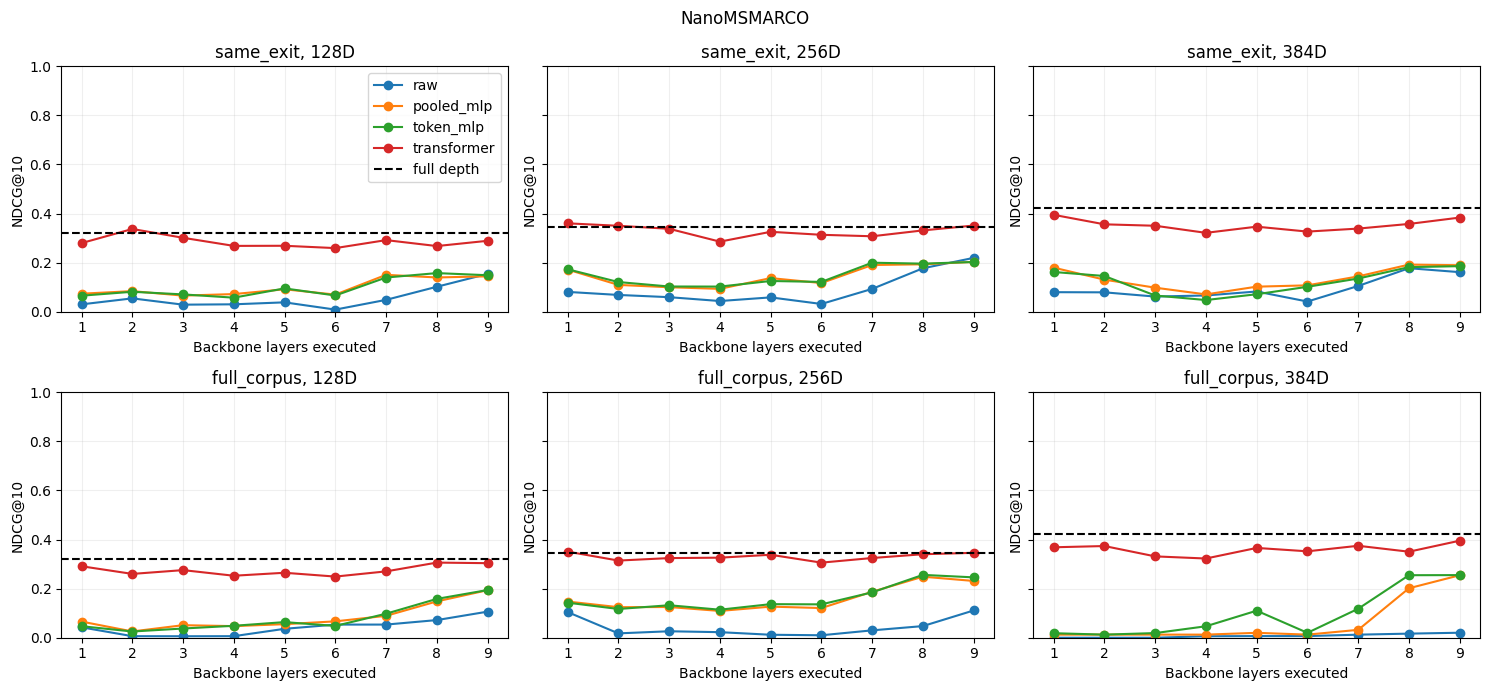

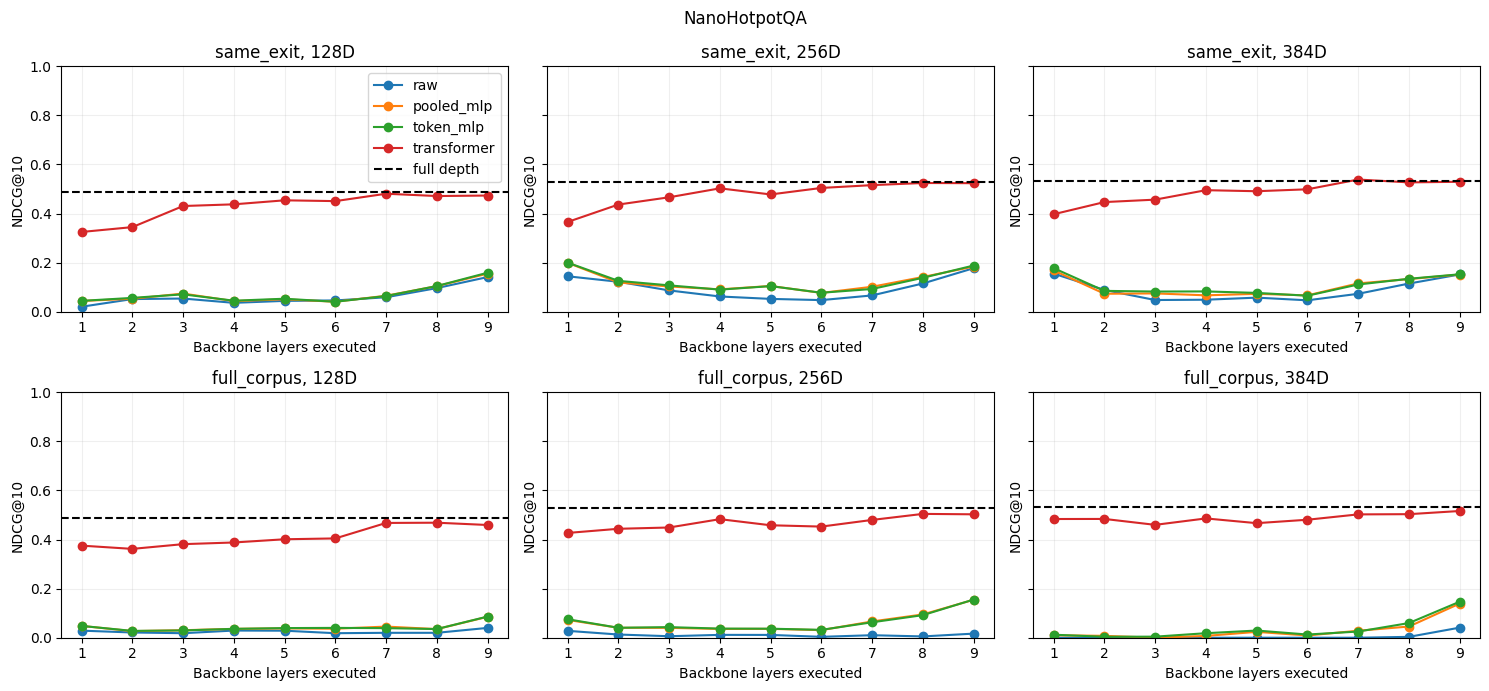

In [15]:
# Plot seed means; CSV retains every individual seed and metric.
for dataset in load_benchmarks():
    fig,axes=plt.subplots(2,len(DIMS),figsize=(5*len(DIMS),7),squeeze=False,sharey=True)
    for row,mode in enumerate(['same_exit','full_corpus']):
        for col,dim in enumerate(DIMS):
            ax=axes[row,col]
            for variant in ['raw']+KINDS:
                ys=[]
                for depth in DEPTHS:
                    scores=[r['ndcg@10'] for r in RESULTS if r['dataset']==dataset and r['mode']==mode and r['dimension']==dim and r['depth']==depth and r['variant']==variant]
                    ys.append(float(np.mean(scores)))
                ax.plot(DEPTHS,ys,marker='o',label=variant)
            full=next(r['ndcg@10'] for r in RESULTS if r['dataset']==dataset and r['variant']=='full' and r['mode']==mode and r['dimension']==dim)
            ax.axhline(full,color='black',ls='--',label='full depth')
            ax.set(title=f'{mode}, {dim}D',xlabel='Backbone layers executed',ylabel='NDCG@10',ylim=(0,1))
            ax.grid(alpha=.2)
    axes[0,0].legend();fig.suptitle(dataset);fig.tight_layout()
    fig.savefig(ROOT/'evaluations'/f'{dataset}-depth-quality.png',dpi=160);plt.show()

## Parameter cost and measured latency

Parameter totals include one shared backbone plus all exits; active parameters include embeddings, the executed prefix,
and only the selected head. Full depth bypasses all branches. Timings use pre-tokenized GPU inputs, BF16, SDPA, CUDA
synchronization, three warmups and repeated measurements. They exclude tokenization, downloads and host/device transfer.
The reported sequence length includes padding. These are GPU measurements, not predictions of CPU/ONNX latency.

In [16]:
def nparams(module):return sum(p.numel() for p in module.parameters())
def cost_rows(bank,label):
    total=nparams(backbone)+(nparams(bank) if bank is not None else 0)
    rows=[]
    for depth in DEPTHS+[NUM_LAYERS]:
        active=nparams(backbone.embeddings)+sum(nparams(b) for b in backbone.layers[:depth])
        extra=0 if bank is None or depth==NUM_LAYERS else nparams(bank.heads[str(depth)])
        active+=nparams(backbone.final_norm) if extra==0 else extra
        rows.append(dict(variant=label,depth=depth,active_parameters=active,head_parameters=extra,
                         stored_parameters=total,fp32_weight_bytes=4*total))
    return rows

@torch.inference_mode()
def measure_latency(bank,label):
    rows=[]
    depths=DEPTHS+[NUM_LAYERS]
    for batch in LATENCY_BATCHES:
        for requested_length in LATENCY_LENGTHS:
            length=min(requested_length,CFG['max_length'])
            tokens=tokenizer(['A document about account settings and recovering a password. '*length]*batch,
                             padding='max_length',truncation=True,max_length=length,return_tensors='pt').to(DEVICE)
            for depth in depths:
                with torch.autocast('cuda',dtype=torch.bfloat16):
                    for _ in range(3):early_raw(tokens,depth,bank)
                    torch.cuda.synchronize();times=[]
                    for _ in range(LATENCY_REPEATS):
                        start=torch.cuda.Event(enable_timing=True);end=torch.cuda.Event(enable_timing=True)
                        start.record();early_raw(tokens,depth,bank);end.record();end.synchronize()
                        times.append(start.elapsed_time(end))
                median=float(np.median(times))
                rows.append(dict(variant=label,depth=depth,batch=batch,length=length,median_ms=median,
                                 p95_ms=float(np.percentile(times,95)),texts_per_second=1000*batch/median))
    return rows

COSTS=cost_rows(None,'raw');LATENCIES=measure_latency(None,'raw') if RUN_LATENCY else []
for kind in KINDS:
    bank=selected_bank(kind,SEEDS[0]);COSTS.extend(cost_rows(bank,kind))
    if RUN_LATENCY:LATENCIES.extend(measure_latency(bank,kind))
    del bank;gc.collect();torch.cuda.empty_cache()
write_json(ROOT/'evaluations'/'cost-latency.json',dict(gpu=torch.cuda.get_device_name(),torch=torch.__version__,
           seed=SEEDS[0],dimensions_share_encoding=True,tokenization_included=False,costs=COSTS,latencies=LATENCIES))
for label in ['raw']+KINDS:
    row=next(r for r in COSTS if r['variant']==label)
    print(label,'stored parameters:',f"{row['stored_parameters']:,}",'FP32 weight MB:',round(row['fp32_weight_bytes']/1e6,1))
if LATENCIES:
    print('Latency: variant / depth / batch / length / median ms')
    for r in LATENCIES:print(r['variant'],r['depth'],r['batch'],r['length'],round(r['median_ms'],3))

Selected pooled_mlp-seed-42 validation-best step 300
Selected token_mlp-seed-42 validation-best step 300
Selected transformer-seed-42 validation-best step 300
raw stored parameters: 31,883,136 FP32 weight MB: 127.5
pooled_mlp stored parameters: 37,205,376 FP32 weight MB: 148.8
token_mlp stored parameters: 37,205,376 FP32 weight MB: 148.8
transformer stored parameters: 43,173,888 FP32 weight MB: 172.7
Latency: variant / depth / batch / length / median ms
raw 1 1 32 2.412
raw 2 1 32 3.182
raw 3 1 32 3.988
raw 4 1 32 4.951
raw 5 1 32 5.842
raw 6 1 32 6.53
raw 7 1 32 8.898
raw 8 1 32 8.358
raw 9 1 32 8.934
raw 10 1 32 12.776
raw 1 1 128 3.398
raw 2 1 128 3.516
raw 3 1 128 5.255
raw 4 1 128 5.16
raw 5 1 128 6.029
raw 6 1 128 6.894
raw 7 1 128 7.717
raw 8 1 128 8.534
raw 9 1 128 9.427
raw 10 1 128 10.257
raw 1 1 256 2.64
raw 2 1 256 3.497
raw 3 1 256 4.329
raw 4 1 256 5.15
raw 5 1 256 5.958
raw 6 1 256 6.813
raw 7 1 256 7.608
raw 8 1 256 8.478
raw 9 1 256 9.334
raw 10 1 256 10.138
raw 1 16 3

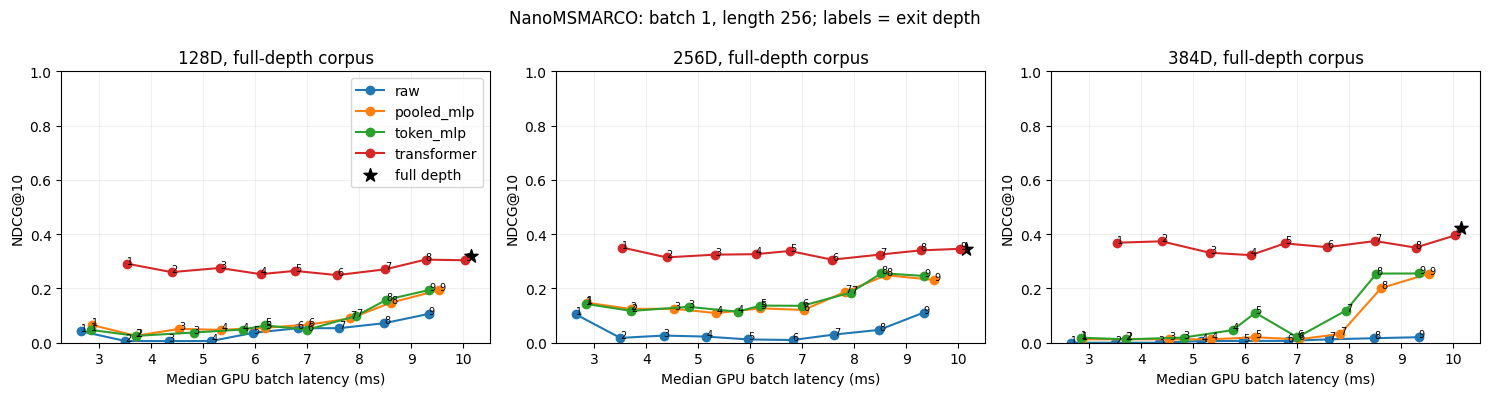

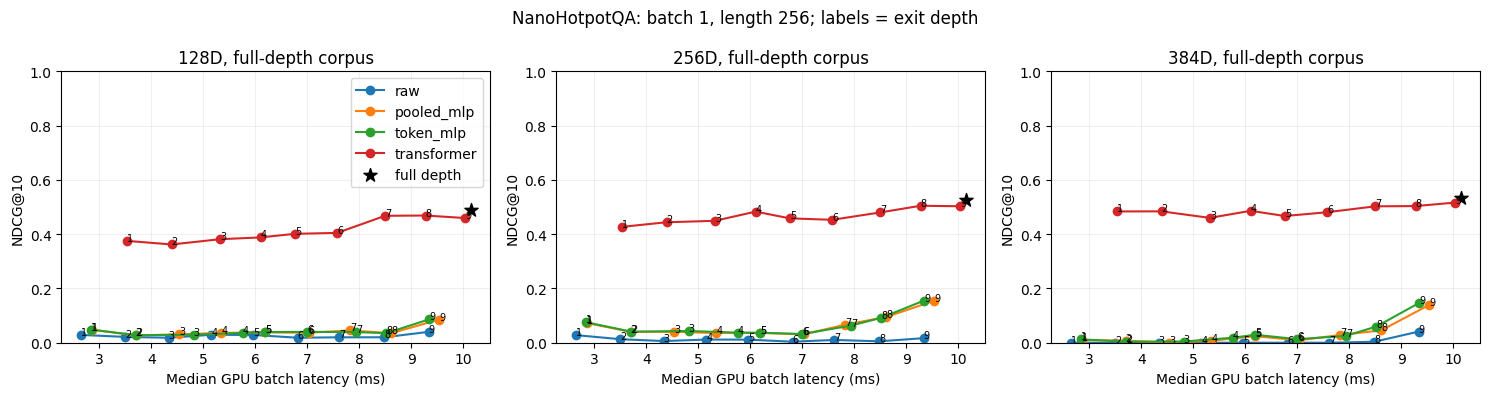

Combined comparison: /content/drive/MyDrive/encoder_experiments/ettin-exit-ablation-01/evaluations/quality-cost-latency.csv


In [17]:
# Combine measured runtime, parameter cost and quality into a sortable table.
# Every dimension shares encoding latency; prefix normalization/search costs are not timed.
COMPARISON=[]
for row in RESULTS:
    label='raw' if row['variant']=='full' else row['variant']
    cost=next(x for x in COSTS if x['variant']==label and x['depth']==row['depth'])
    timings=[x for x in LATENCIES if x['variant']==label and x['depth']==row['depth']] or [None]
    for timing in timings:
        item=dict(row,active_parameters=cost['active_parameters'],stored_parameters=cost['stored_parameters'],
                  batch=timing['batch'] if timing else None,length=timing['length'] if timing else None,
                  median_ms=timing['median_ms'] if timing else None,
                  texts_per_second=timing['texts_per_second'] if timing else None,
                  latency_seed=SEEDS[0] if timing else None)
        COMPARISON.append(item)
with open(ROOT/'evaluations'/'quality-cost-latency.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(COMPARISON[0]));writer.writeheader();writer.writerows(COMPARISON)
if LATENCIES:
    display_batch=LATENCY_BATCHES[0]
    display_length=min(LATENCY_LENGTHS[-1],CFG['max_length'])
    for dataset in load_benchmarks():
        fig,axes=plt.subplots(1,len(DIMS),figsize=(5*len(DIMS),4),squeeze=False)
        for col,dim in enumerate(DIMS):
            ax=axes[0,col]
            for variant in ['raw']+KINDS:
                xs=[];ys=[]
                for depth in DEPTHS:
                    rows=[r for r in COMPARISON if r['dataset']==dataset and r['variant']==variant and
                          r['depth']==depth and r['dimension']==dim and r['mode']=='full_corpus' and
                          r['batch']==display_batch and r['length']==display_length]
                    xs.append(rows[0]['median_ms']);ys.append(float(np.mean([r['ndcg@10'] for r in rows])))
                ax.plot(xs,ys,marker='o',label=variant)
                for x,y,depth in zip(xs,ys,DEPTHS):ax.annotate(str(depth),(x,y),fontsize=7)
            full=next(r for r in COMPARISON if r['dataset']==dataset and r['variant']=='full' and
                      r['dimension']==dim and r['mode']=='full_corpus' and r['batch']==display_batch and r['length']==display_length)
            ax.scatter([full['median_ms']],[full['ndcg@10']],marker='*',s=100,color='black',label='full depth')
            ax.set(title=f'{dim}D, full-depth corpus',xlabel='Median GPU batch latency (ms)',ylabel='NDCG@10',ylim=(0,1))
            ax.grid(alpha=.2)
        axes[0,0].legend();fig.suptitle(f'{dataset}: batch {display_batch}, length {display_length}; labels = exit depth')
        fig.tight_layout();fig.savefig(ROOT/'evaluations'/f'{dataset}-quality-latency.png',dpi=160);plt.show()
print('Combined comparison:',ROOT/'evaluations'/'quality-cost-latency.csv')

## Portable weights and reload checks

The bundle stores the backbone once, a tokenizer, head safetensors, source provenance, and selected steps.
Reload it with the definitions in this notebook; it is not an ONNX export. The pilot's training-only GTE alignment head
is omitted. Each bank contains all its exit heads, so deployment can later retain just the chosen exits.

In [18]:
EXPORT=ROOT/'exports'/'exit-ablation'
if not EXPORT.exists():
    temp=ROOT/'exports'/('.uploading-'+uuid.uuid4().hex);temp.mkdir(parents=True)
    backbone.save_pretrained(temp/'backbone',safe_serialization=True);tokenizer.save_pretrained(temp/'tokenizer')
    shutil.copyfile(hf_hub_download(ETTIN['id'],'README.md',revision=ETTIN['revision']),temp/'UPSTREAM_MODEL_CARD.md')
    write_json(temp/'encoder.json',dict(contract=contract,source=ETTIN,supervisor=GTE,backbone_sha=BACKBONE_SHA,
               pooling='original_final_norm_then_masked_mean',normalize_after_truncation=True,max_length=CFG['max_length'],
               selected=SELECTED,head_definitions='ExitBank and ExitHead in 04_ettin_exit_ablations.ipynb'))
    for seed in SEEDS:
        for kind in KINDS:
            bank=selected_bank(kind,seed)
            save_file({k:v.detach().cpu().contiguous() for k,v in bank.state_dict().items()},str(temp/f'{kind}-seed-{seed}.safetensors'))
            del bank
    os.replace(temp,EXPORT)
else:assert json.loads((EXPORT/'encoder.json').read_text())['contract']==contract

# Reload the independent backbone once; compare it with the original selected source path.
reloaded_backbone=AutoModel.from_pretrained(EXPORT/'backbone',attn_implementation='sdpa').to(DEVICE).eval()
reloaded_tokenizer=AutoTokenizer.from_pretrained(EXPORT/'tokenizer')
probe=['Recover a forgotten password.','Books are available at the library.']
tokens=tokenize(probe)
reload_tokens=reloaded_tokenizer(probe,padding=True,truncation=True,max_length=CFG['max_length'],return_tensors='pt').to(DEVICE)
assert all(torch.equal(tokens[k],reload_tokens[k]) for k in tokens)
with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
    expected=student(probe)
    restored=mean_pool(reloaded_backbone(**reload_tokens).last_hidden_state,reload_tokens['attention_mask'])
torch.testing.assert_close(expected,restored,atol=1e-5,rtol=1e-4)
del reloaded_backbone;gc.collect();torch.cuda.empty_cache()
for seed in SEEDS:
    for kind in KINDS:
        bank=selected_bank(kind,seed);reload_bank=ExitBank(kind,seed).to(DEVICE).eval()
        reload_bank.load_state_dict(load_file(str(EXPORT/f'{kind}-seed-{seed}.safetensors')),strict=True)
        with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
            for depth in DEPTHS:
                a=early_raw(tokens,depth,bank).float();b=early_raw(tokens,depth,reload_bank).float()
                for dim in DIMS:torch.testing.assert_close(F.normalize(a[:,:dim],dim=-1),F.normalize(b[:,:dim],dim=-1),atol=1e-5,rtol=1e-4)
        del bank,reload_bank
assert backbone_digest()==BACKBONE_SHA
print('Backbone + every exit/prefix export parity passed:',EXPORT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected pooled_mlp-seed-42 validation-best step 300
Selected token_mlp-seed-42 validation-best step 300
Selected transformer-seed-42 validation-best step 300


Loading weights:   0%|          | 0/62 [00:00<?, ?it/s]

Selected pooled_mlp-seed-42 validation-best step 300
Selected token_mlp-seed-42 validation-best step 300
Selected transformer-seed-42 validation-best step 300
Backbone + every exit/prefix export parity passed: /content/drive/MyDrive/encoder_experiments/ettin-exit-ablation-01/exports/exit-ablation


## Reading the experiment

Compare held-out retrieval **and measured latency**, rather than choosing the lowest distillation loss.
A strong same-exit result with weak full-corpus retrieval means the exit learned a different coordinate space;
it may require rebuilding the corpus index. Late transformer exits may cost as much as the full model.
A flat or poor earliest-layer curve is a useful result: frozen heads cannot force the trunk to compute missing features.
Only trained/evaluated depths and dimensions have evidence; “any layer” does not promise equal quality.

Academic motivation: [2D Matryoshka](https://arxiv.org/abs/2402.14776),
[FastBERT](https://aclanthology.org/2020.acl-main.537/),
[EE-Tuning](https://arxiv.org/abs/2402.00518), and
[Matryoshka-Adaptor](https://aclanthology.org/2024.emnlp-main.576/).
The loss combination and its application to this small Ettin encoder are experimental adaptations, not paper reproductions.

## Final independent sanity check
Authored probes, repeatability, padding invariance, full-path preservation, and every exit/prefix. Run this bottom cell after the comparison.

In [19]:
SANITY_CASES = [
    ('I forgot my account password.', 'Use the password reset link to regain access to your account.',
     'The tomato plants need watering every morning.'),
    ('How can I get my money back for this purchase?', 'Request a refund for your order through customer support.',
     'The train leaves the station at six in the evening.'),
    ('My phone battery runs out too quickly.', 'Reduce screen brightness and background apps to extend battery life.',
     'The museum has opened a new exhibition of ancient pottery.'),
    ('How do I bake a loaf of bread?', 'Mix flour, water and yeast, let the dough rise, then bake it in the oven.',
     'The football team won the championship yesterday.'),
    ('I want to cancel my monthly subscription.', 'Open your billing settings and choose cancel subscription.',
     'Migrating birds travel south during the winter.'),
    ('My laptop cannot connect to Wi-Fi.', 'Check the wireless network settings and restart your router.',
     'The orchestra performed a symphony at the concert hall.'),
    ('How can I track the package I ordered?', 'Enter your parcel tracking number to see its delivery status.',
     'Stretching your legs before a run can help improve flexibility.'),
    ('How do I change the language in the app?', 'Choose your preferred display language in the application settings.',
     'The recipe calls for two eggs and a cup of milk.'),
    ('I need to book a visit with a doctor.', 'Contact the clinic to schedule a medical appointment.',
     'The new telescope can observe distant galaxies.'),
    ('Where can I find books to borrow?', 'Visit the public library to check out books with your library card.',
     'The car needs new tires before the road trip.'),
    ('How can I recover a file that I deleted?', 'Look in the recycle bin or restore the document from a backup.',
     'The beach is covered in shells after the tide goes out.'),
    ('I want to learn to play the guitar.', 'Practice basic chords and strumming patterns on your guitar each day.',
     'The city council approved construction of a new bridge.'),
]

def sanity_scores(raw, cases, dimensions):
    # Pure scoring function: no model, tokenizer or teacher dependency.
    raw = raw.detach().float().cpu()
    n = len(cases)
    assert raw.ndim == 2 and len(raw) == 3*n
    finite = bool(torch.isfinite(raw).all())
    norms = raw.norm(dim=-1)
    nonzero = finite and bool((norms > 1e-8).all())
    result = dict(finite=finite, nonzero=nonzero,
                  raw_norm_min=float(norms.min()) if finite else None,
                  raw_norm_mean=float(norms.mean()) if finite else None,
                  profiles={})
    if not nonzero:
        return result
    for dim in dimensions:
        prefix_norms = raw[:, :dim].norm(dim=-1)
        z = F.normalize(raw[:, :dim], dim=-1)
        q, positive, unrelated = z.split(n)
        pos = (q*positive).sum(-1); neg = (q*unrelated).sum(-1)
        scores = q @ torch.cat((positive, unrelated)).T
        positive_mask = torch.zeros_like(scores, dtype=torch.bool)
        positive_mask[torch.arange(n), torch.arange(n)] = True
        # Conservative tie handling: a collapsed model must not pass by index order.
        ranks = 1 + ((scores >= pos[:,None]-1e-6) & ~positive_mask).sum(-1)
        pairwise = z @ z.T
        offdiag = pairwise[~torch.eye(len(z),dtype=torch.bool)]
        result['profiles'][str(dim)] = dict(
            nonzero_prefix=bool((prefix_norms > 1e-8).all()),
            easy_accuracy=float((pos > neg+1e-6).float().mean()),
            mean_margin=float((pos-neg).mean()),
            hit_at_1=float((ranks <= 1).float().mean()),
            hit_at_5=float((ranks <= 5).float().mean()),
            mrr=float((1/ranks.float()).mean()),
            normalized_spread=float((z-z.mean(0)).square().sum(-1).mean()),
            off_diagonal_cosine_mean=float(offdiag.mean()),
            examples=[dict(query=cases[i][0], positive=cases[i][1], unrelated=cases[i][2],
                           positive_cosine=float(pos[i]), unrelated_cosine=float(neg[i]),
                           positive_rank=int(ranks[i]), easy_correct=bool(pos[i]>neg[i]+1e-6))
                      for i in range(n)])
    return result


@torch.inference_mode()
def exit_sanity(bank,label,seed):
    if bank is not None:bank.eval()
    texts=[case[i] for i in range(3) for case in SANITY_CASES]
    vectors=encode_profiles(texts,bank)
    reports=[]
    for depth in DEPTHS+([NUM_LAYERS] if bank is None else []):
        report=sanity_scores(vectors[depth],SANITY_CASES,DIMS)
        short=SANITY_CASES[0][0];long='A longer passage describing a library, its books, the weather, and plans for a journey. '*3
        with torch.autocast('cuda',dtype=torch.bfloat16):
            a=early_raw(tokenize([short]),depth,bank).float()
            repeat=early_raw(tokenize([short]),depth,bank).float()
            padded=early_raw(tokenize([short,long]),depth,bank)[:1].float()
        repeat_ok=bool(torch.allclose(a,repeat,atol=1e-5,rtol=1e-4))
        padding={str(dim):float(F.cosine_similarity(a[:,:dim],padded[:,:dim]).item()) for dim in DIMS}
        passed=report['finite'] and report['nonzero'] and repeat_ok and all(v>.999 for v in padding.values()) and all(v['nonzero_prefix'] for v in report['profiles'].values())
        report.update(variant=label,seed=seed,depth=depth,repeatable=repeat_ok,padding_cosines=padding,plumbing_passed=bool(passed))
        reports.append(report)
        for dim,r in report['profiles'].items():
            print(f"{label:12} seed={str(seed):4} L={depth:2} D={dim:>3} plumbing={'PASS' if passed else 'FAIL'} easy={r['easy_accuracy']:.1%} hit1={r['hit_at_1']:.1%} spread={r['normalized_spread']:.4f}")
    return reports

SANITY=exit_sanity(None,'raw',None)
for seed in SEEDS:
    for kind in KINDS:
        bank=selected_bank(kind,seed);SANITY.extend(exit_sanity(bank,kind,seed));del bank
unchanged=backbone_digest()==BACKBONE_SHA
path=ROOT/'evaluations'/f'sanity-{time.time_ns()}.json'
write_json(path,dict(contract=CONTRACT_ID,source=source_info,backbone_unchanged=unchanged,reports=SANITY))
print('Saved:',path,'\nSanity probes are diagnostic; use held-out retrieval and latency for model selection.')
assert unchanged and all(r['plumbing_passed'] for r in SANITY), 'Plumbing failed; inspect saved report.'

raw          seed=None L= 1 D=128 plumbing=PASS easy=83.3% hit1=16.7% spread=0.5071
raw          seed=None L= 1 D=256 plumbing=PASS easy=75.0% hit1=25.0% spread=0.5530
raw          seed=None L= 1 D=384 plumbing=PASS easy=83.3% hit1=33.3% spread=0.0400
raw          seed=None L= 2 D=128 plumbing=PASS easy=83.3% hit1=16.7% spread=0.3339
raw          seed=None L= 2 D=256 plumbing=PASS easy=91.7% hit1=25.0% spread=0.3132
raw          seed=None L= 2 D=384 plumbing=PASS easy=83.3% hit1=25.0% spread=0.0232
raw          seed=None L= 3 D=128 plumbing=PASS easy=83.3% hit1=33.3% spread=0.3694
raw          seed=None L= 3 D=256 plumbing=PASS easy=91.7% hit1=33.3% spread=0.3093
raw          seed=None L= 3 D=384 plumbing=PASS easy=83.3% hit1=25.0% spread=0.0369
raw          seed=None L= 4 D=128 plumbing=PASS easy=83.3% hit1=33.3% spread=0.3954
raw          seed=None L= 4 D=256 plumbing=PASS easy=91.7% hit1=25.0% spread=0.2795
raw          seed=None L= 4 D=384 plumbing=PASS easy=83.3% hit1=33.3% spread